In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer
X,y = load_breast_cancer(return_X_y=True, as_frame=True)

In [2]:
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.4, random_state=1, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_hold, y_hold, test_size=0.5, random_state=1, stratify=y_hold)

# Get a ROC curve for a random forest model. Here, I use a scatterplot to manually construct the ROC instead of using a built-in ROC function. 

Start by defining the classifier. Changing max depth will change the final ROC curve.

In [3]:
forest_mod = RandomForestClassifier(n_estimators=500, max_depth=10, random_state=1)
forest_mod.fit(X_train, y_train)

print('Training Accuracy:  ', round(forest_mod.score(X_train, y_train),4))
print('Validation Accuracy:', round(forest_mod.score(X_valid, y_valid),4))

Training Accuracy:   1.0
Validation Accuracy: 0.9298


## YOU DO: 

In [18]:
def get_fpr(preds, truths):
  fp = 0
  n = 0
  for i in range(len(preds)):
    if truths[i] == 0:
      n += 1
      if preds[i] == 1:
        fp += 1
  if n==0:
    return 0
  return fp/n

def get_tpr(preds, truths):
  tp = 0
  p = 0
  for i in range(len(preds)):
    if truths[i] == 1:
      p += 1
      if preds[i] == 1:
        tp += 1
  if p == 0:
    return 0
  return tp/p

Use the forest model on the test set to see the FPR and TPR. Plot on a scatterplot (ROC curve)

['0.20', '0.25', '0.30', '0.35', '0.40', '0.45', '0.50', '0.55', '0.60', '0.65', '0.70', '0.75', '0.80']


Text(0, 0.5, 'TPR')

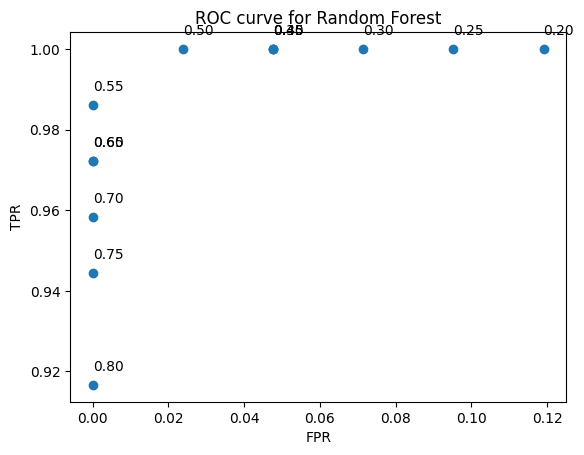

In [24]:
probs = forest_mod.predict_proba(X_test)[:, 1]  # Probability of positive class
x = [] # FPR
y = [] # TPR
labels = []
truths = list(y_test)

# Iterate over thresholds to put together a ROC curve by hand
for t in np.arange(0.2, 0.8, 0.05):
  preds = (probs >= t).astype(int)
  x.append(get_fpr(preds,truths))  # YOUR CODE HERE
  y.append(get_tpr(preds,truths))  # YOUR CODE HERE
  labels.append("{:.2f}".format(t))
print(labels)

# Plot the ROC curve
plt.scatter(x, y)
for i, label in enumerate(labels): #add threshold labels to the points
    plt.annotate(
        label,
        (x[i], y[i]),
        textcoords="offset points",
        xytext=(0, 10))
plt.title("ROC curve for Random Forest")
plt.xlabel("FPR")
plt.ylabel("TPR")


# TODO: add axis labels  

## Questions to Answer

1. What value of the threshold would you choose if you want to make sure that no cancers are missed?
0.5
2. What value of the threshold would you choose if you want to make sure that all detected cancers are truly cancers and not false positives? 
0.55
3. What happens if you use a very small max_depth in the random forest (eg 4 or smaller)? Why? 
when the max depth decreases, the predictability of the model also decreases. in terms of ROC, the curve will become flatter.